# Real Estate Housing Price Prediction (Ridge & Lasso Regression)

### Task 2 — Datheon Machine Learning & Data Science Internship

## Project Objective
Predict median house values using the California Housing dataset and compare regression models.

## Models
1. Linear Regression (OLS)
2. Ridge Regression (L2)
3. Lasso Regression (L1)

## Project Workflow
1. Load and explore the California Housing dataset.
2. Handle missing values and engineer features.
3. Analyze correlations and standardize features.
4. Train Linear Regression, Ridge, and Lasso models.
5. Tune hyperparameters using GridSearchCV.
6. Evaluate models using RMSE, MAE, and R².
7. Visualize predictions and residual errors.

## 1. Importing Required Libraries

Import the necessary Python libraries for data manipulation, visualization, preprocessing, regression modeling, hyperparameter tuning, and model evaluation.

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.linear_model import LinearRegression, Ridge, Lasso

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

## 2. Loading the Dataset

Load the California Housing dataset using Pandas and display the first five rows to understand its structure and features.

In [2]:
# Load the California Housing dataset
df = pd.read_csv("california_housing.csv")

# Display the first 5 rows
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## 3. Exploratory Data Analysis (EDA)

Explore the dataset to understand its structure, data types, summary statistics, and missing values before preprocessing and model training.

In [3]:
# Check the number of rows and columns
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns)

# Display dataset information
print("\nDataset Information:")
df.info()

# Display statistical summary
print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (20640, 10)

Column Names:
Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


## 4. Missing Value Analysis

Check the dataset for missing values to identify incomplete records and determine the appropriate preprocessing techniques.

In [4]:
# Check missing values in each column
print("Missing Values in Each Column:")
print(df.isnull().sum())

# Check total missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values in Each Column:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Total Missing Values: 207


## 5. Handling Missing Values

Missing values can affect model training and prediction accuracy.

We will use **median imputation** to replace missing numerical values with the median of their respective columns.

To prevent data leakage, the imputer will be fitted only on the training data using a Scikit-learn Pipeline.

## 6. Feature Engineering

Feature engineering involves creating new features from existing dataset columns to improve the model's ability to identify patterns.

We will create three additional features:

1. **Rooms per Household** — Average number of rooms per household.
2. **Bedrooms per Room** — Proportion of bedrooms relative to total rooms.
3. **Population per Household** — Average number of people per household.

These features may help improve housing price predictions.

In [5]:
# Create new features

df["rooms_per_household"] = df["total_rooms"] / df["households"]

df["bedrooms_per_room"] = df["total_bedrooms"] / df["total_rooms"]

df["population_per_household"] = df["population"] / df["households"]

# Display the updated dataset
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,rooms_per_household,bedrooms_per_room,population_per_household
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,6.984127,0.146591,2.555556
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,6.238137,0.155797,2.109842
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,8.288136,0.129516,2.802260
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,5.817352,0.184458,2.547945
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,6.281853,0.172096,2.181467


## 7. Correlation Analysis

Correlation analysis helps identify relationships between numerical features and the target variable (`median_house_value`).

We will use a **correlation heatmap** to visualize these relationships and understand which features are strongly associated with housing prices.

Correlation values range from **-1 to +1**:

- **+1:** Perfect positive correlation.
- **0:** No linear correlation.
- **-1:** Perfect negative correlation.

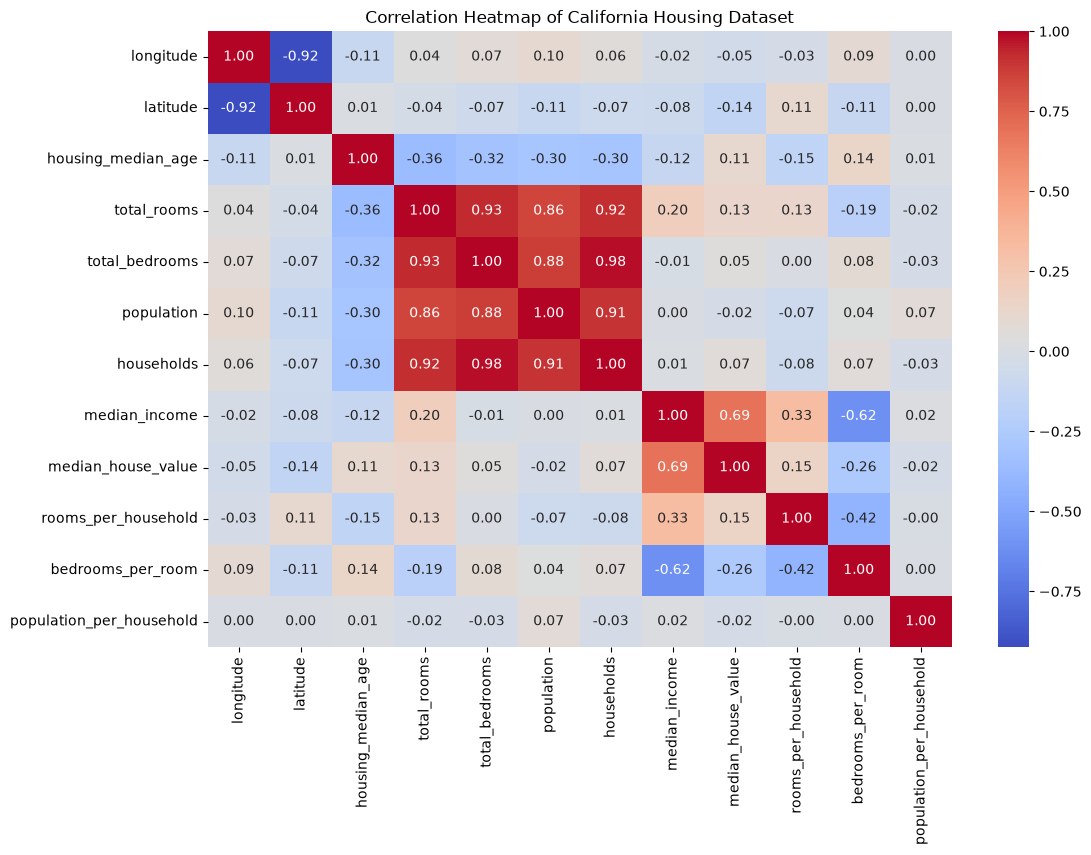

In [6]:
# Calculate correlation between numerical features
correlation_matrix = df.corr(numeric_only=True)

# Set figure size
plt.figure(figsize=(12, 8))

# Create correlation heatmap
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

# Add title
plt.title("Correlation Heatmap of California Housing Dataset")

# Display the heatmap
plt.show()

## 8. Preparing Features and Target Variable

Separate the dataset into independent features (X) and the target variable (y).

- **X (Features):** Input variables used to predict housing prices.
- **y (Target):** `median_house_value`, the value our models will predict.

Categorical features will be encoded into numerical form before model training.

In [7]:
# Separate features and target variable

X = df.drop("median_house_value", axis=1)

y = df["median_house_value"]

# Display shapes
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

# Display first 5 rows of features
display(X.head())

Features Shape: (20640, 12)
Target Shape: (20640,)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity,rooms_per_household,bedrooms_per_room,population_per_household
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,NEAR BAY,6.984127,0.146591,2.555556
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,NEAR BAY,6.238137,0.155797,2.109842
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,NEAR BAY,8.288136,0.129516,2.802260
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,NEAR BAY,5.817352,0.184458,2.547945
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,NEAR BAY,6.281853,0.172096,2.181467


## 9. Splitting the Dataset

Split the dataset into training (80%) and testing (20%) sets using `train_test_split()`.

- **Training Set (80%):** Used to train the regression models.
- **Testing Set (20%):** Used to evaluate model performance on unseen data.

We use `random_state=42` to ensure reproducible results.

Preprocessing transformations will be fitted only on the training data to prevent data leakage.

In [8]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Display the shapes
print("X_train Shape:", X_train.shape)
print("X_test Shape:", X_test.shape)
print("y_train Shape:", y_train.shape)
print("y_test Shape:", y_test.shape)

X_train Shape: (16512, 12)
X_test Shape: (4128, 12)
y_train Shape: (16512,)
y_test Shape: (4128,)


## 10. Data Preprocessing Pipeline

Prepare the dataset for machine learning using Scikit-learn preprocessing techniques.

The preprocessing pipeline will perform three operations:

1. **Missing Value Imputation:** Replace missing numerical values using median imputation.
2. **Categorical Encoding:** Convert the `ocean_proximity` column into numerical features using OneHotEncoder.
3. **Feature Scaling:** Standardize numerical features using StandardScaler.

These transformations will be fitted only on the training data to prevent data leakage.

In [9]:
# Identify numerical and categorical columns
numerical_features = X_train.select_dtypes(include=["int64", "float64"]).columns
categorical_features = X_train.select_dtypes(include=["object", "category"]).columns

# Handle missing values and scale numerical features
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Handle categorical features
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


C:\Users\DELL\AppData\Local\Temp\ipykernel_13824\1123284082.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(include=["object", "category"]).columns


## 11. Linear Regression (OLS)

Linear Regression is a supervised machine learning algorithm used to predict continuous numerical values.

We will train a **Linear Regression (Ordinary Least Squares)** model as our baseline.

The model learns relationships between housing features and median house values by minimizing the sum of squared prediction errors.

This baseline will help us evaluate the performance of Ridge and Lasso Regression.

In [10]:
# Check for infinite values in numerical features
numeric_columns = X_train.select_dtypes(include=np.number).columns

print("Infinite values in training data:",
      np.isinf(X_train[numeric_columns].to_numpy()).sum())

print("Infinite values in testing data:",
      np.isinf(X_test[numeric_columns].to_numpy()).sum())

# Replace infinite values with NaN
X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

# Create Linear Regression pipeline
linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

# Train the model
linear_model.fit(X_train, y_train)

# Make predictions
y_pred_linear = linear_model.predict(X_test)

print("Linear Regression model trained successfully!")

Infinite values in training data: 0
Infinite values in testing data: 0
Linear Regression model trained successfully!


## 12. Ridge Regression (L2 Regularization)

Ridge Regression is a linear regression technique that uses **L2 regularization** to reduce overfitting.

Unlike ordinary Linear Regression, Ridge adds a penalty for large model coefficients.

The strength of regularization is controlled by a hyperparameter called **alpha (α)**.

- **α = 0:** Equivalent to ordinary least squares in its objective.
- **Small α:** Weak regularization.
- **Large α:** Strong regularization.

We will train a Ridge Regression model and compare its performance with Linear Regression.

In [11]:
# Create Ridge Regression pipeline
ridge_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=1.0))
])

# Train Ridge Regression model
ridge_model.fit(X_train, y_train)

# Make predictions
y_pred_ridge = ridge_model.predict(X_test)

print("Ridge Regression model trained successfully!")

Ridge Regression model trained successfully!


## 13. Lasso Regression (L1 Regularization)

Lasso Regression is a linear regression technique that uses **L1 regularization** to reduce overfitting and perform feature selection.

Unlike Ridge Regression, Lasso can shrink some feature coefficients to exactly zero, effectively removing their influence from the model.

The regularization strength is controlled by **alpha (α)**.

- **Small α:** Weak regularization.
- **Large α:** Stronger regularization.
- **Feature Selection:** Some coefficients may become zero.

We will train a Lasso Regression model and compare its performance with Linear Regression and Ridge Regression.

In [12]:
# Create Lasso Regression pipeline
lasso_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Lasso(alpha=1.0, max_iter=10000))
])

# Train Lasso Regression model
lasso_model.fit(X_train, y_train)

# Make predictions
y_pred_lasso = lasso_model.predict(X_test)

print("Lasso Regression model trained successfully!")

Lasso Regression model trained successfully!


## 14. Hyperparameter Tuning using GridSearchCV

Hyperparameter tuning helps identify the best model settings to improve predictive performance.

We will use **GridSearchCV** to find suitable alpha (α) values for Ridge and Lasso Regression.

GridSearchCV evaluates different alpha values using **5-fold cross-validation**.

The best alpha values will be selected based on cross-validation performance, without using the test dataset.

In [13]:
# Define alpha values
alpha_values = [0.01, 0.1, 1, 10, 100]

# Hyperparameter tuning for Ridge Regression
ridge_grid = GridSearchCV(
    estimator=ridge_model,
    param_grid={"model__alpha": alpha_values},
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

# Train Ridge GridSearchCV
ridge_grid.fit(X_train, y_train)

# Display best alpha
print("Best Ridge Alpha:", ridge_grid.best_params_)


# Hyperparameter tuning for Lasso Regression
lasso_grid = GridSearchCV(
    estimator=lasso_model,
    param_grid={"model__alpha": alpha_values},
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

# Train Lasso GridSearchCV
lasso_grid.fit(X_train, y_train)

# Display best alpha
print("Best Lasso Alpha:", lasso_grid.best_params_)

Best Ridge Alpha: {'model__alpha': 1}
Best Lasso Alpha: {'model__alpha': 1}


## 15. Model Evaluation

Evaluate the performance of Linear Regression, Ridge Regression, and Lasso Regression using three evaluation metrics:

1. **Root Mean Squared Error (RMSE):** Measures prediction error while giving greater weight to large errors.
2. **Mean Absolute Error (MAE):** Measures the average absolute difference between actual and predicted values.
3. **R² Score:** Measures how well the model explains variation in housing values.

We will evaluate all three models using the same test dataset to ensure a fair comparison.

For Ridge and Lasso, we will use the best models selected by GridSearchCV.

In [14]:
# Get predictions from the tuned models
y_pred_ridge_tuned = ridge_grid.predict(X_test)
y_pred_lasso_tuned = lasso_grid.predict(X_test)

# Function to evaluate regression models
def evaluate_model(name, y_actual, y_pred):
    mae = mean_absolute_error(y_actual, y_pred)
    rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
    r2 = r2_score(y_actual, y_pred)

    return {
        "Model": name,
        "RMSE": rmse,
        "MAE": mae,
        "R2 Score": r2
    }

# Evaluate all three models
results = [
    evaluate_model("Linear Regression", y_test, y_pred_linear),
    evaluate_model("Ridge Regression", y_test, y_pred_ridge_tuned),
    evaluate_model("Lasso Regression", y_test, y_pred_lasso_tuned)
]

# Convert results into a DataFrame
results_df = pd.DataFrame(results)

# Display model performance
display(results_df.round(4))

,Model,RMSE,MAE,R2 Score
0,Linear Regression,69127.0383,49645.4924,0.6353
1,Ridge Regression,69134.9653,49652.1429,0.6353
2,Lasso Regression,69128.0912,49646.4289,0.6353


## 16. Model Performance Comparison

Compare the performance of Linear Regression, Ridge Regression, and Lasso Regression using RMSE, MAE, and R² scores.

We will visualize the evaluation results using bar charts to identify the best-performing regression model.

The model with the lowest test RMSE will be considered the best-performing model for this comparison.

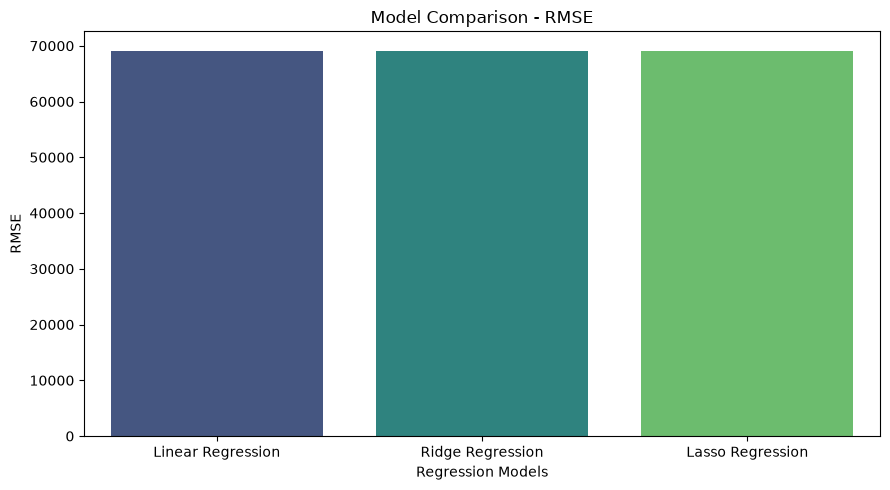

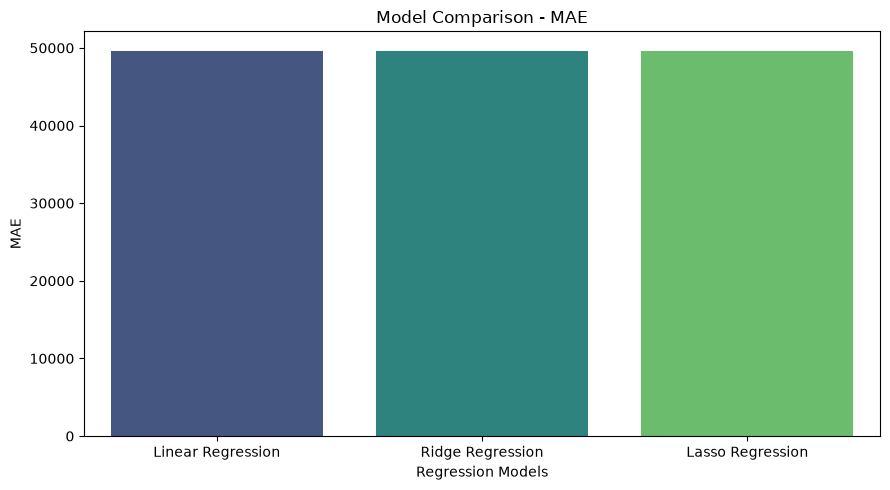

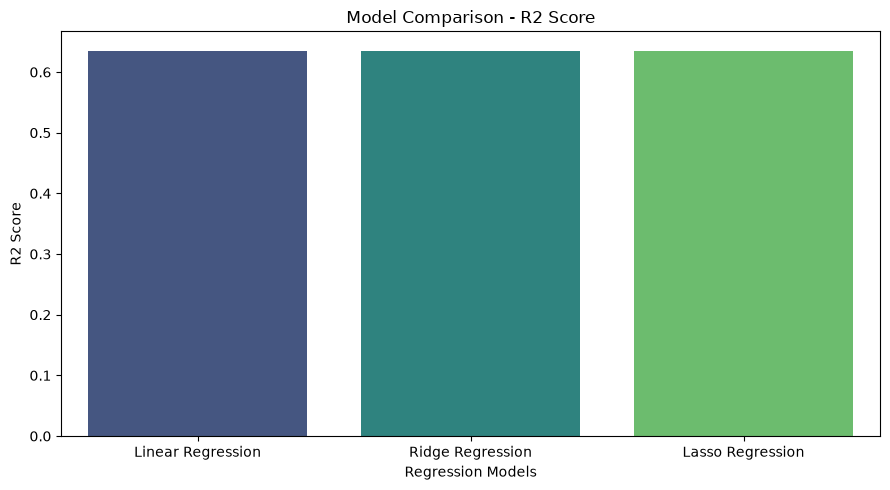

In [15]:
# Set up evaluation metrics
metrics = ["RMSE", "MAE", "R2 Score"]

# Create bar charts for each metric
for metric in metrics:
    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=results_df,
        x="Model",
        y=metric,
        hue="Model",
        palette="viridis",
        legend=False
    )

    plt.title(f"Model Comparison - {metric}")
    plt.xlabel("Regression Models")
    plt.ylabel(metric)

    plt.tight_layout()
    plt.show()

## 17. Actual vs. Predicted Values

Visualize the relationship between actual and predicted housing values using scatter plots.

We will compare the predictions of Linear Regression, Ridge Regression, and Lasso Regression.

A diagonal reference line represents perfect predictions. Points closer to this line indicate more accurate predictions.

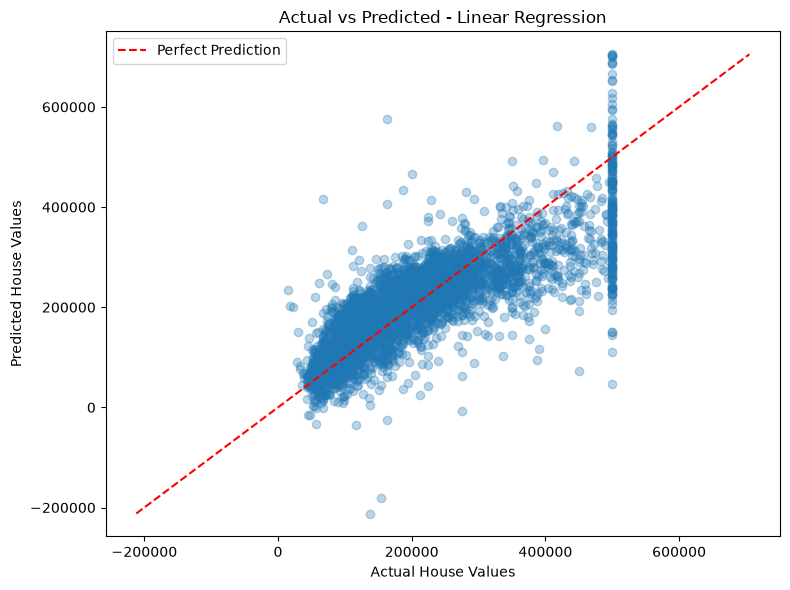

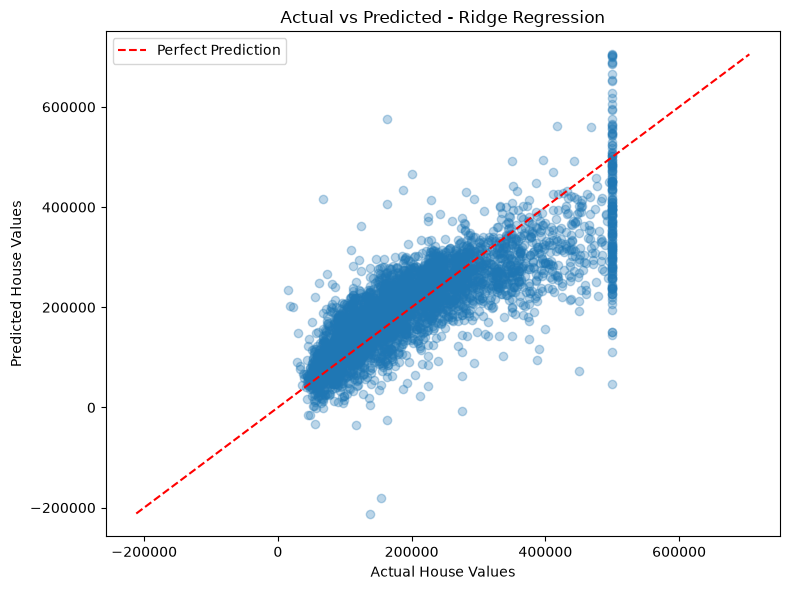

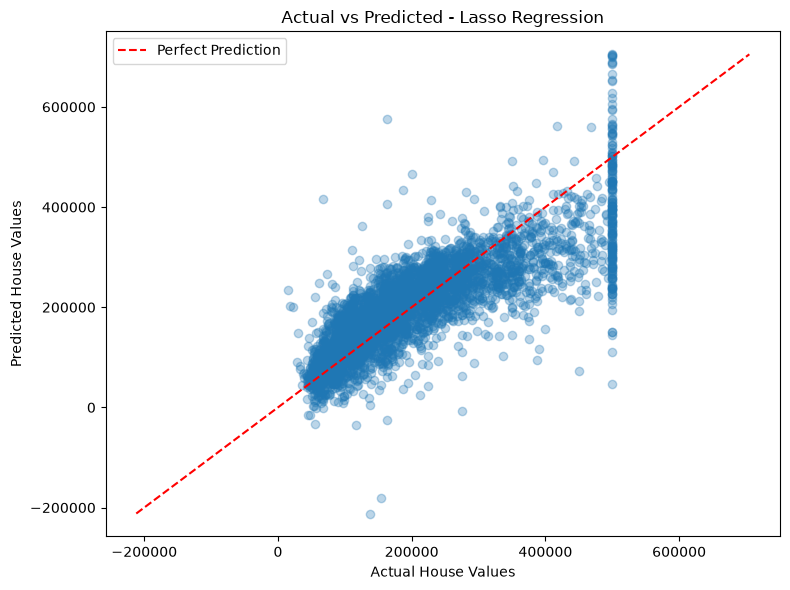

In [16]:
# Store predictions from all three models
predictions = {
    "Linear Regression": y_pred_linear,
    "Ridge Regression": y_pred_ridge_tuned,
    "Lasso Regression": y_pred_lasso_tuned
}

# Create Actual vs Predicted plots
for model_name, y_pred in predictions.items():

    plt.figure(figsize=(8, 6))

    # Scatter plot
    plt.scatter(y_test, y_pred, alpha=0.3)

    # Perfect prediction reference line
    min_value = min(y_test.min(), y_pred.min())
    max_value = max(y_test.max(), y_pred.max())

    plt.plot(
        [min_value, max_value],
        [min_value, max_value],
        color="red",
        linestyle="--",
        label="Perfect Prediction"
    )

    plt.xlabel("Actual House Values")
    plt.ylabel("Predicted House Values")
    plt.title(f"Actual vs Predicted - {model_name}")

    plt.legend()
    plt.tight_layout()
    plt.show()

## 18. Residual Analysis

Residual analysis helps evaluate regression models by examining the differences between actual and predicted housing values.

A residual is calculated as:

**Residual = Actual Value − Predicted Value**

We will visualize residual distributions and residuals versus predicted values for Linear Regression, Ridge Regression, and Lasso Regression.

Ideally, residuals should be randomly distributed around zero without clear patterns. This helps us identify potential model limitations, systematic errors, and unusual predictions.

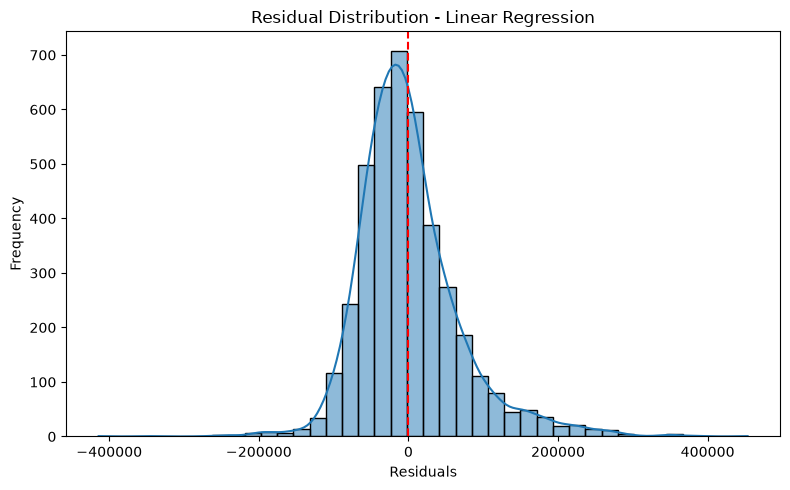

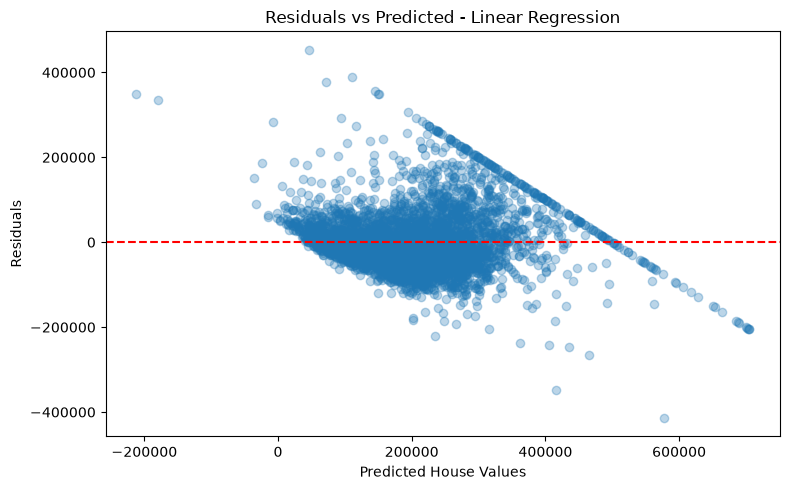

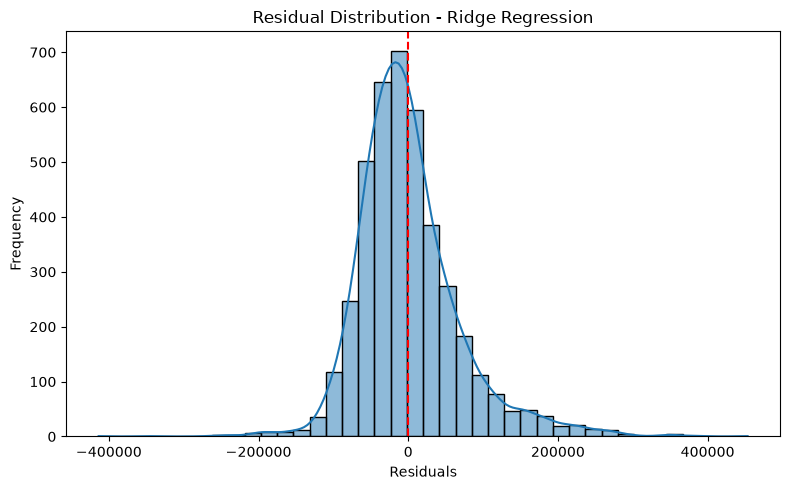

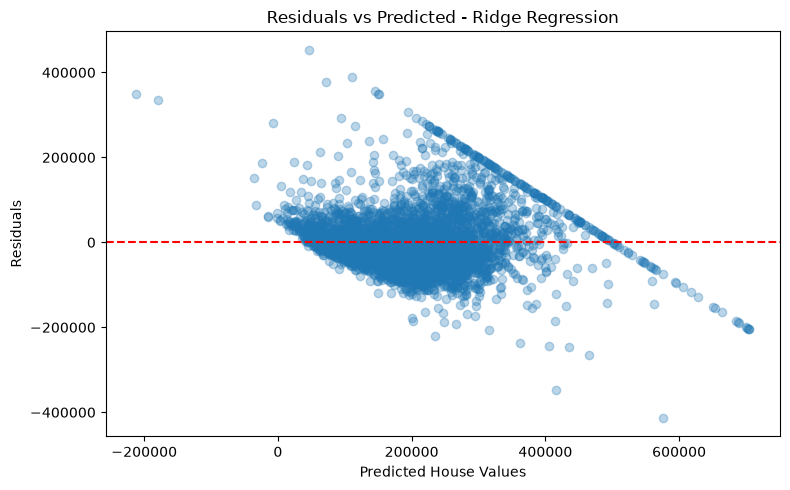

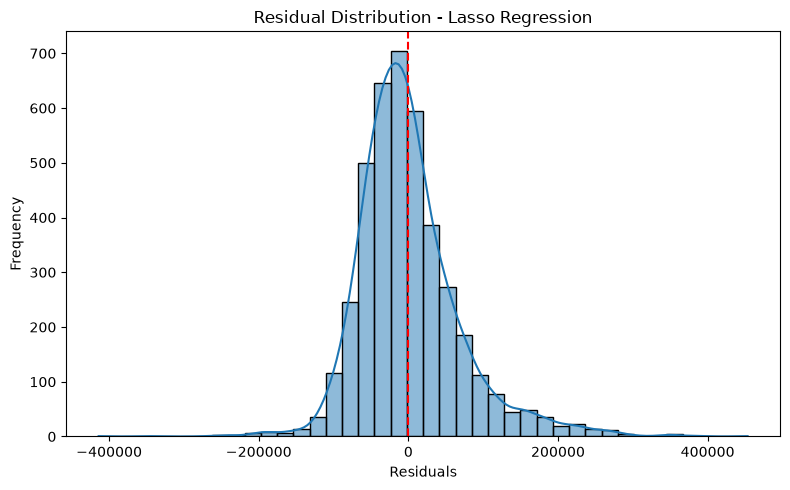

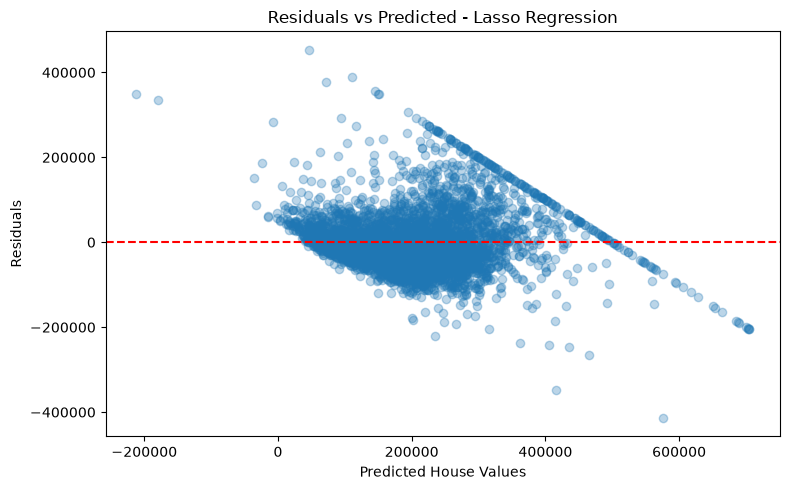

In [17]:
# Residual Analysis for all three models

for model_name, y_pred in predictions.items():

    # Calculate residuals
    residuals = y_test.to_numpy() - y_pred

    # 1. Residual Distribution
    plt.figure(figsize=(8, 5))

    sns.histplot(residuals, bins=40, kde=True)

    plt.axvline(0, color="red", linestyle="--")

    plt.title(f"Residual Distribution - {model_name}")
    plt.xlabel("Residuals")
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

    # 2. Residuals vs Predicted Values
    plt.figure(figsize=(8, 5))

    plt.scatter(y_pred, residuals, alpha=0.3)

    plt.axhline(0, color="red", linestyle="--")

    plt.title(f"Residuals vs Predicted - {model_name}")
    plt.xlabel("Predicted House Values")
    plt.ylabel("Residuals")

    plt.tight_layout()
    plt.show()

## 19. Final Results and Conclusion

### Project Overview

This project developed and evaluated three regression models to predict median housing values using the California Housing dataset.

### Models Implemented

1. **Linear Regression:** Established a baseline for housing value prediction.
2. **Ridge Regression:** Applied L2 regularization to reduce the impact of large coefficients.
3. **Lasso Regression:** Applied L1 regularization, which can shrink some feature coefficients to zero.

### Key Accomplishments

- Performed exploratory data analysis (EDA).
- Identified missing values and handled them using median imputation.
- Created additional features to improve the representation of housing characteristics.
- Applied feature scaling and categorical encoding.
- Split the dataset into training and testing sets.
- Trained Linear Regression, Ridge Regression, and Lasso Regression models.
- Used GridSearchCV to tune regularization parameters.
- Evaluated models using RMSE, MAE, and R².
- Visualized model predictions and residuals.

### Model Evaluation

The models were compared using three evaluation metrics:

- **RMSE:** Measures prediction error while giving greater weight to large errors.
- **MAE:** Measures the average absolute prediction error.
- **R² Score:** Measures how much variation in housing values is explained by the model.

The model with the lowest test RMSE is identified as the best-performing model in this comparison.

### Conclusion

This project demonstrated how regression techniques can be applied to a real-world housing dataset.

Ridge and Lasso Regression provide regularization techniques that can help control model complexity and reduce overfitting.

The evaluation results and visualizations allow us to compare the strengths and limitations of each model.


In [18]:
# Final Model Performance Summary

print("=" * 55)
print("HOUSING PRICE PREDICTION - FINAL RESULTS")
print("=" * 55)

# Display performance comparison
print("\nModel Performance Comparison:")
display(results_df.round(4))

# Identify the best model based on lowest RMSE
best_model = results_df.loc[results_df["RMSE"].idxmin()]

print("\n" + "=" * 55)
print("BEST PERFORMING MODEL")
print("=" * 55)

print("Model:", best_model["Model"])
print("RMSE:", round(best_model["RMSE"], 2))
print("MAE:", round(best_model["MAE"], 2))
print("R² Score:", round(best_model["R2 Score"], 4))

print("\nProject completed successfully!")

HOUSING PRICE PREDICTION - FINAL RESULTS

Model Performance Comparison:


,Model,RMSE,MAE,R2 Score
0,Linear Regression,69127.0383,49645.4924,0.6353
1,Ridge Regression,69134.9653,49652.1429,0.6353
2,Lasso Regression,69128.0912,49646.4289,0.6353



BEST PERFORMING MODEL
Model: Linear Regression
RMSE: 69127.04
MAE: 49645.49
R² Score: 0.6353

Project completed successfully!
